In [2]:
!pip install pandas numpy scikit-learn matplotlib

  Using cached contourpy-1.3.3-cp311-cp311-win_amd64.whl.metadata (5.5 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached kiwisolver-1.5.1-cp311-cp311-win_amd64.whl.metadata (5.2 kB)
  Using cached pillow-12.3.0-cp311-cp311-win_amd64.whl.metadata (9.3 kB)
   ---------------------------------------- 0.0/9.3 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.3 MB ? eta -:--:--
   ---- ----------------------------------- 1.0/9.3 MB 3.1 MB/s eta 0:00:03
   ------ --------------------------------- 1.6/9.3 MB 2.8 MB/s eta 0:00:03
   -------- ------------------------------- 2.1/9.3 MB 2.9 MB/s eta 0:00:03
   ------------ --------------------------- 2.9/9.3 MB 3.1 MB/s eta 0:00:03
   ------------- -------------------------- 3.1/9.3 MB 2.8 MB/s eta 0:00:03
   --------------- ------------------------ 3.7/9.3 MB 2.5 MB/s eta 0:00:03
   ---------------- ----------------------- 3.9/9.3 MB 2.4 MB/s eta 0:00:03
   ----------------- ---------------------

In [26]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error

In [28]:
import os
# Robust path to support running from notebooks/ or project root
dataset_path = "../data/shipments.csv" if os.path.exists("../data/shipments.csv") else "data/shipments.csv"
data = pd.read_csv(dataset_path)

print(data.shape)
display(data.head())


(300, 20)


,shipment_id,origin,destination,transport_mode,scheduled_departure,actual_departure,scheduled_port_arrival,actual_port_arrival,scheduled_customs_completion,actual_customs_completion,scheduled_delivery,actual_delivery,port_congestion_level,weather_severity,customs_workload,departure_delay_hours,port_arrival_delay_hours,customs_delay_hours,final_delay_hours,delay_status
0,SHP-0001,Rotterdam,Shanghai,Ocean,2026-01-22 20:45:00,2026-01-22 20:49:12,2026-02-22 16:45:00,2026-02-22 08:22:48,2026-02-23 20:45:00,2026-02-23 22:56:24,2026-02-24 20:45:00,2026-02-25 02:06:00,High,Mild,Medium,0.07,-8.37,2.19,5.35,On-Time
1,SHP-0002,Shanghai,Los Angeles,Ocean,2026-05-25 05:45:00,2026-05-25 05:51:36,2026-06-09 05:45:00,2026-06-09 01:58:48,2026-06-10 05:45:00,2026-06-10 20:42:00,2026-06-11 05:45:00,2026-06-11 22:13:48,High,Mild,Medium,0.11,-3.77,14.95,16.48,Delayed
2,SHP-0003,Singapore,Rotterdam,Air,2026-02-17 19:15:00,2026-02-17 17:25:12,2026-02-19 01:15:00,2026-02-18 23:13:12,2026-02-19 15:15:00,2026-02-19 10:49:48,2026-02-20 03:15:00,2026-02-19 22:58:12,Low,Mild,Medium,-1.83,-2.03,-4.42,-4.28,On-Time
3,SHP-0004,Singapore,Rotterdam,Ocean,2026-01-28 08:15:00,2026-01-28 05:54:00,2026-02-20 08:15:00,2026-02-20 09:40:12,2026-02-21 10:15:00,2026-02-21 07:01:48,2026-02-22 10:15:00,2026-02-22 04:10:48,Low,Mild,Medium,-2.35,1.42,-3.22,-6.07,On-Time
4,SHP-0005,Shanghai,Rotterdam,Multimodal,2026-05-12 15:30:00,2026-05-12 15:30:36,2026-05-28 11:30:00,2026-05-28 10:08:24,2026-05-29 11:30:00,2026-05-29 05:28:48,2026-05-30 11:30:00,2026-05-30 07:07:48,Low,Mild,Medium,0.01,-1.36,-6.02,-4.37,On-Time


In [29]:
print("Number of rows and columns:", data.shape)

print("\nColumn names:")
print(data.columns.tolist())

print("\nMissing values:")
display(data.isnull().sum())

print("\nDataset statistics:")
display(data.describe(include="all").T)

print("\nDelay status:")
display(data["delay_status"].value_counts())

Number of rows and columns: (300, 20)

Column names:
['shipment_id', 'origin', 'destination', 'transport_mode', 'scheduled_departure', 'actual_departure', 'scheduled_port_arrival', 'actual_port_arrival', 'scheduled_customs_completion', 'actual_customs_completion', 'scheduled_delivery', 'actual_delivery', 'port_congestion_level', 'weather_severity', 'customs_workload', 'departure_delay_hours', 'port_arrival_delay_hours', 'customs_delay_hours', 'final_delay_hours', 'delay_status']

Missing values:


shipment_id                      0
origin                           0
destination                      0
transport_mode                   0
scheduled_departure              0
actual_departure                21
scheduled_port_arrival           0
actual_port_arrival             21
scheduled_customs_completion     0
actual_customs_completion       21
scheduled_delivery               0
actual_delivery                  0
port_congestion_level            0
weather_severity                 0
customs_workload                 0
departure_delay_hours           21
port_arrival_delay_hours        21
customs_delay_hours             21
final_delay_hours                0
delay_status                     0
dtype: int64


Dataset statistics:


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
shipment_id,300,300,SHP-0001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
origin,300,5,Shanghai,93,NaN,NaN,NaN,NaN,NaN,NaN,NaN
destination,300,5,Rotterdam,117,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transport_mode,300,3,Ocean,149,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scheduled_departure,300,300,2026-01-22 20:45:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
actual_departure,279,279,2026-01-22 20:49:12,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scheduled_port_arrival,300,297,2026-04-11 17:15:00,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
actual_port_arrival,279,279,2026-02-22 08:22:48,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
scheduled_customs_completion,300,300,2026-02-23 20:45:00,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
actual_customs_completion,279,279,2026-02-23 22:56:24,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Delay status:


delay_status
On-Time    185
Delayed    115
Name: count, dtype: int64

In [30]:
data["scheduled_departure"] = pd.to_datetime(
    data["scheduled_departure"], errors="coerce"
)

data["scheduled_delivery"] = pd.to_datetime(
    data["scheduled_delivery"], errors="coerce"
)

data["journey_hours"] = (
    data["scheduled_delivery"] - data["scheduled_departure"]
).dt.total_seconds() / 3600

data["departure_month"] = data["scheduled_departure"].dt.month

print("Features created successfully!")
display(data[["journey_hours", "departure_month"]].head())

Features created successfully!


,journey_hours,departure_month
0,792.0,1
1,408.0,5
2,56.0,2
3,602.0,1
4,428.0,5


In [31]:
features = [
    "origin",
    "destination",
    "transport_mode",
    "port_congestion_level",
    "weather_severity",
    "customs_workload",
    "journey_hours",
    "departure_month"
]

X = data[features].copy()
y = pd.to_numeric(data["final_delay_hours"], errors="coerce")

# Remove records without a known target
valid_rows = y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

print("Input features:", features)
print("Records available:", len(X))

Input features: ['origin', 'destination', 'transport_mode', 'port_congestion_level', 'weather_severity', 'customs_workload', 'journey_hours', 'departure_month']
Records available: 300


In [32]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

Training records: 240
Testing records: 60


In [33]:
X_train = pd.get_dummies(X_train)
X_test = pd.get_dummies(X_test)

# Make sure training and testing columns match
X_test = X_test.reindex(
    columns=X_train.columns,
    fill_value=0
)

# Fill missing values using training data only
medians = X_train.median()

X_train = X_train.fillna(medians)
X_test = X_test.fillna(medians)

print("Training data shape:", X_train.shape)
print("Testing data shape:", X_test.shape)

Training data shape: (240, 24)
Testing data shape: (60, 24)


In [34]:
model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

print("ETA prediction model trained successfully!")

ETA prediction model trained successfully!


In [35]:
# Random Forest predictions
predictions = model.predict(X_test)

# Baseline predictions
baseline = DummyRegressor(strategy="median")
baseline.fit(X_train, y_train)

baseline_predictions = baseline.predict(X_test)

# Evaluation metrics
baseline_mae = mean_absolute_error(y_test, baseline_predictions)
model_mae = mean_absolute_error(y_test, predictions)

model_rmse = np.sqrt(
    mean_squared_error(y_test, predictions)
)

print("Baseline MAE:", round(baseline_mae, 2), "hours")
print("Random Forest MAE:", round(model_mae, 2), "hours")
print("Random Forest RMSE:", round(model_rmse, 2), "hours")

Baseline MAE: 15.93 hours
Random Forest MAE: 8.01 hours
Random Forest RMSE: 12.37 hours


In [36]:
results = pd.DataFrame({
    "Actual delay (hours)": y_test,
    "Predicted delay (hours)": predictions
})

results["Absolute error (hours)"] = (
    results["Actual delay (hours)"]
    - results["Predicted delay (hours)"]
).abs()

display(results.head(10).round(2))

,Actual delay (hours),Predicted delay (hours),Absolute error (hours)
203,24.05,17.85,6.20
266,0.28,3.05,2.77
152,70.44,67.15,3.29
9,-11.71,-12.44,0.73
233,16.64,17.63,0.99
226,2.96,4.23,1.27
196,7.39,-9.46,16.85
109,24.46,5.34,19.12
5,-8.54,-2.29,6.25
175,7.22,7.95,0.73


weather_severity_Severe       0.515861
journey_hours                 0.110745
transport_mode_Air            0.056923
port_congestion_level_High    0.052279
departure_month               0.034146
weather_severity_Mild         0.029418
weather_severity_Moderate     0.028439
transport_mode_Ocean          0.027660
customs_workload_High         0.026273
customs_workload_Low          0.025278
dtype: float64

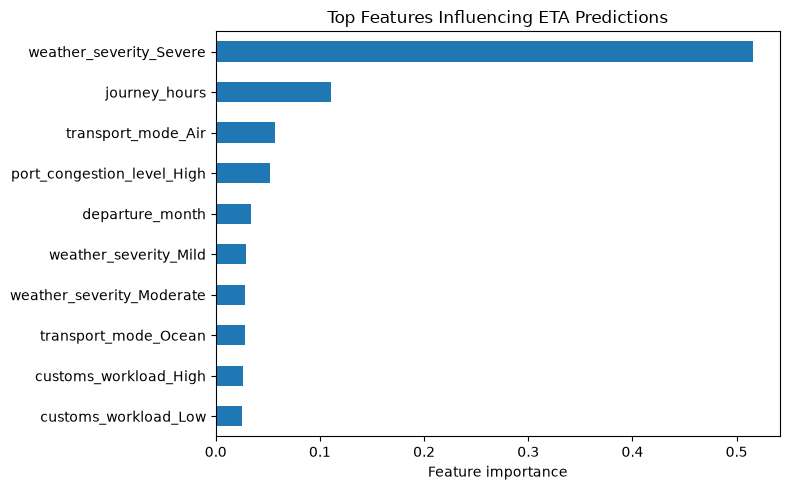

In [37]:
importance = pd.Series(
    model.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

display(importance.head(10))

importance.head(10).sort_values().plot(
    kind="barh",
    figsize=(8, 5)
)

plt.title("Top Features Influencing ETA Predictions")
plt.xlabel("Feature importance")
plt.tight_layout()
plt.show()

In [38]:
eta_results = pd.DataFrame(index=X_test.index)

eta_results["Scheduled ETA"] = pd.to_datetime(
    data.loc[X_test.index, "scheduled_delivery"]
)

eta_results["Actual ETA"] = pd.to_datetime(
    data.loc[X_test.index, "actual_delivery"],
    errors="coerce"
)

eta_results["Predicted delay (hours)"] = predictions

eta_results["Predicted ETA"] = (
    eta_results["Scheduled ETA"]
    + pd.to_timedelta(predictions, unit="h")
)

display(eta_results.head(10).round(2))

C:\Users\sanka\AppData\Local\Temp\ipykernel_40220\2533243939.py:19: UserWarning: obj.round has no effect with datetime, timedelta, or period dtypes. Use obj.dt.round(...) instead.
  display(eta_results.head(10).round(2))


,Scheduled ETA,Actual ETA,Predicted delay (hours),Predicted ETA
203,2026-02-09 00:30:00,2026-02-10 00:33:00,17.85,2026-02-09 18:21:14.640000001
266,2026-01-12 04:45:00,2026-01-12 05:01:48,3.05,2026-01-12 07:48:03.960000000
152,2026-02-27 15:00:00,2026-03-02 13:26:24,67.15,2026-03-02 10:09:11.256000001
9,2026-05-04 11:00:00,2026-05-03 23:17:24,-12.44,2026-05-03 22:33:48.960000000
233,2026-03-23 11:45:00,2026-03-24 04:23:24,17.63,2026-03-24 05:22:38.640000000
226,2026-03-28 02:45:00,2026-03-28 05:42:36,4.23,2026-03-28 06:58:49.500000001
196,2026-04-08 02:00:00,2026-04-08 09:23:24,-9.46,2026-04-07 16:32:37.860000000
109,2026-05-21 14:30:00,2026-05-22 14:57:36,5.34,2026-05-21 19:50:38.400000000
5,2026-01-20 11:00:00,2026-01-20 02:27:36,-2.29,2026-01-20 08:42:41.598000000
175,2026-05-09 16:45:00,2026-05-09 23:58:12,7.95,2026-05-10 00:41:44.304000000


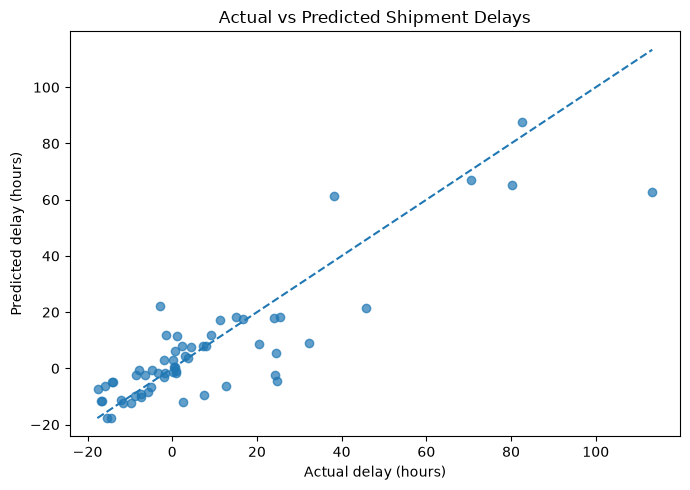

In [39]:
plt.figure(figsize=(7, 5))

plt.scatter(y_test, predictions, alpha=0.7)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot(
    [lower, upper],
    [lower, upper],
    linestyle="--"
)

plt.xlabel("Actual delay (hours)")
plt.ylabel("Predicted delay (hours)")
plt.title("Actual vs Predicted Shipment Delays")
plt.tight_layout()
plt.show()

In [40]:
stage_delays = [
    "departure_delay_hours",
    "port_arrival_delay_hours",
    "customs_delay_hours",
    "final_delay_hours"
]

display(data[stage_delays].describe().round(2))

,departure_delay_hours,port_arrival_delay_hours,customs_delay_hours,final_delay_hours
count,279.00,279.00,279.00,300.00
mean,3.32,11.26,8.14,8.13
std,6.81,22.12,24.02,23.86
min,-2.48,-9.11,-26.39,-25.29
25%,-0.18,-0.16,-6.19,-6.08
50%,0.71,2.10,1.08,1.55
75%,5.28,12.96,14.90,14.24
max,35.84,106.72,112.74,113.34


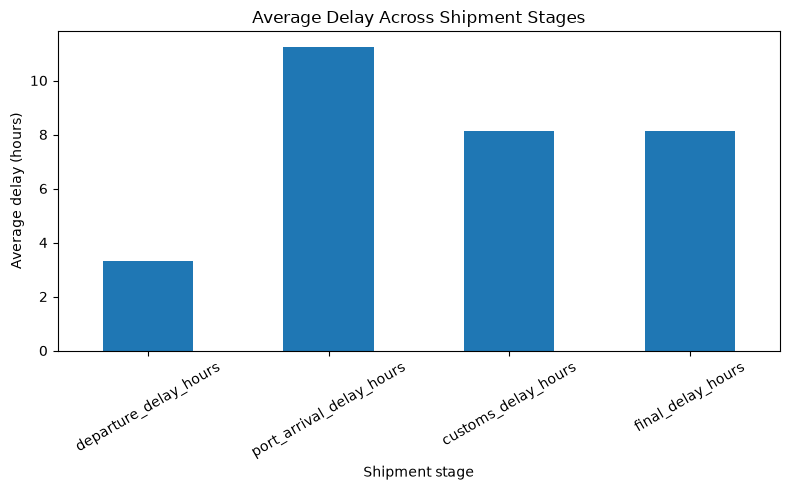

,departure_delay_hours,port_arrival_delay_hours,customs_delay_hours,final_delay_hours
departure_delay_hours,1.00,0.28,0.25,0.25
port_arrival_delay_hours,0.28,1.00,0.92,0.91
customs_delay_hours,0.25,0.92,1.00,1.00
final_delay_hours,0.25,0.91,1.00,1.00


In [41]:
data[stage_delays].mean().plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Average Delay Across Shipment Stages")
plt.ylabel("Average delay (hours)")
plt.xlabel("Shipment stage")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(data[stage_delays].corr().round(2))

In [42]:
print("Baseline MAE:", round(baseline_mae, 2), "hours")
print("Random Forest MAE:", round(model_mae, 2), "hours")
print("Random Forest RMSE:", round(model_rmse, 2), "hours")

Baseline MAE: 15.93 hours
Random Forest MAE: 8.01 hours
Random Forest RMSE: 12.37 hours
